In [3]:
import argparse
import os
import sys
import random
import timeit
import datetime

import numpy as np
import torch.nn.functional as F
import pickle
import scipy.misc
# import utils.scipymisc as m
import matplotlib.pyplot as plt
import imageio.v2 as imageio
# import skimage
from PIL import Image

import torch
import cv2
import kornia

In [13]:
void_classes = [0, 1, 2, 3, 4, 5, 6, 9, 10, 14, 15, 16, 18, 29, 30, -1]
valid_classes = [7, 8, 11, 12, 13, 17, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 31, 32, 33,]

IMG_MEAN = np.array((104.00698793, 116.66876762, 122.67891434), dtype=np.float32)

ignore_index = 250
class_map = dict(zip(valid_classes, range(19)))

def encode_segmap(mask):
        # Put all void classes to zero
        for _voidc in void_classes:
            mask[mask == _voidc] = ignore_index
        for _validc in valid_classes:
            mask[mask == _validc] = class_map[_validc]
        return mask

def colorJitter(colorJitter, img_mean, data = None, target = None, s=0.25):
    # s is the strength of colorjitter
    #colorJitter
    if not (data is None):
        if data.shape[1]==3:
            if colorJitter > 0.2:
                img_mean, _ = torch.broadcast_tensors(img_mean.unsqueeze(0).unsqueeze(2).unsqueeze(3), data)
                seq = nn.Sequential(kornia.augmentation.ColorJitter(brightness=s,contrast=s,saturation=s,hue=s))
                data = (data+img_mean)/255
                data = seq(data)
                data = (data*255-img_mean).float()
    return data, target


def generate_class_mask(pred, classes):
    pred, classes = torch.broadcast_tensors(pred.unsqueeze(0), classes.unsqueeze(1).unsqueeze(2))
    N = pred.eq(classes).sum(0)
    return N

def oneMix(mask, data = None, target = None):
    #Mix
    if not (data is None):
        stackedMask0, _ = torch.broadcast_tensors(mask[0], data[0])
        data = (stackedMask0*data[0]+(1-stackedMask0)*data[1]).unsqueeze(0)
    if not (target is None):
        stackedMask0, _ = torch.broadcast_tensors(mask[0], target[0])
        target = (stackedMask0*target[0]+(1-stackedMask0)*target[1]).unsqueeze(0)
    return data, target

def strongTransform(parameters, data=None, target=None):
    assert ((data is not None) or (target is not None))
    data, target = oneMix(mask = parameters["Mix"], data = data, target = target)
    # data, target = colorJitter(colorJitter = parameters["ColorJitter"], img_mean = torch.from_numpy(IMG_MEAN.copy()).cuda(), data = data, target = target)
    # data, target = transformsgpu.gaussian_blur(blur = parameters["GaussianBlur"], data = data, target = target)
    # data, target = transformsgpu.flip(flip = parameters["flip"], data = data, target = target)
    
    return data, target

In [4]:
tgt_img = Image.open('datasets/synthia/RAND_CITYSCAPES/RGB/0000004.png').convert('RGB')

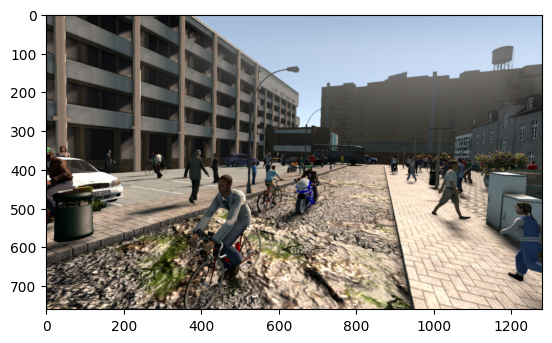

In [8]:
plt.imshow(np.array(tgt_img))
plt.show()

In [3]:
tgt_img_1 = imageio.imread('Imgs/cityscapes_img_bremen_52_19.png')
tgt_img_1 = m.imresize(tgt_img_1, (760, 1280))
tgt_img_1 = np.array(tgt_img_1, dtype=np.uint8)
tgt_img_1 = torch.Tensor(tgt_img_1)

tgt_img_2 = imageio.imread('Imgs/cityscapes_img_bremen_84_19.png')
tgt_img_2 = np.array(tgt_img_2, dtype=np.uint8)
tgt_img_2 = torch.Tensor(tgt_img_2)

src_img_1 = imageio.imread('Imgs/synthia_img_0.png')
src_img_1 = np.array(src_img_1, dtype=np.uint8)
src_img_1 = torch.Tensor(src_img_1)

src_img_2 = imageio.imread('Imgs/synthia_img_101.png')
src_img_2 = np.array(src_img_2, dtype=np.uint8)
src_img_2 = torch.Tensor(src_img_2)


/var/folders/t4/1z7d5z_s17zgbvc34vy5lmn40000gn/T/ipykernel_78563/863876719.py:2: DeprecationWarning:     `imresize` is deprecated!
    `imresize` is deprecated in SciPy 1.0.0, and will be removed in 1.2.0.
    Use ``skimage.transform.resize`` instead.
  tgt_img_1 = m.imresize(tgt_img_1, (760, 1280))


In [4]:
tgt_lbl_1 = imageio.imread('Imgs/cityscapes_label_bremen_52_19.png')
tgt_lbl_1 = np.array(tgt_lbl_1, dtype=np.uint8)
tgt_lbl_1 = encode_segmap(tgt_lbl_1)
tgt_lbl_1 = torch.Tensor(tgt_lbl_1)

tgt_lbl_2 = imageio.imread('Imgs/cityscapes_label_bremen_84_19.png')
tgt_lbl_2 = np.array(tgt_lbl_2, dtype=np.uint8)
tgt_lbl_2 = encode_segmap(tgt_lbl_2)
tgt_lbl_2 = torch.Tensor(tgt_lbl_2)

src_lbl_1 = imageio.imread('Imgs/synthia_label_0.png')
src_lbl_1 = np.array(src_lbl_1, dtype=np.uint8)
src_lbl_1 = encode_segmap(src_lbl_1)
src_lbl_1 = torch.Tensor(src_lbl_1)

src_lbl_2 = imageio.imread('Imgs/synthia_label_101.png')
src_lbl_2 = np.array(src_lbl_2, dtype=np.uint8)
src_lbl_2 = encode_segmap(src_lbl_2)
src_lbl_2 = torch.Tensor(src_lbl_2)

In [119]:
classes = torch.unique(src_lbl_2)
use_list = [4, 5, 6, 7, 11, 12, 13, 14, 15, 17, 18]

classes = torch.Tensor([item for item in classes if item in use_list])

nclasses = classes.shape[0]
#if nclasses > 0:
classes = (classes[torch.Tensor(np.random.choice(nclasses, np.random.randint(1 , max(nclasses - 2, 2) ),replace=False)).long()])


MixMask0 = generate_class_mask(src_lbl_2, torch.Tensor([2])).unsqueeze(0)


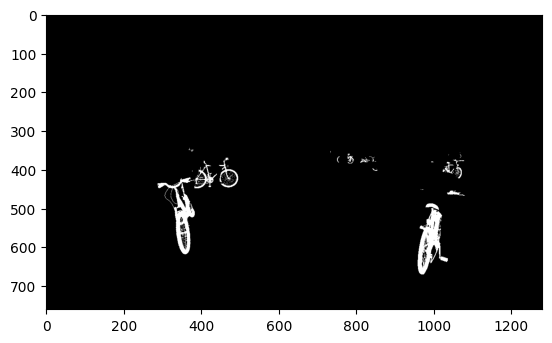

In [137]:
plt.imshow(MixMask0.squeeze(0), cmap='gray')

In [162]:
masked_img.shape

torch.Size([760, 1280, 3])

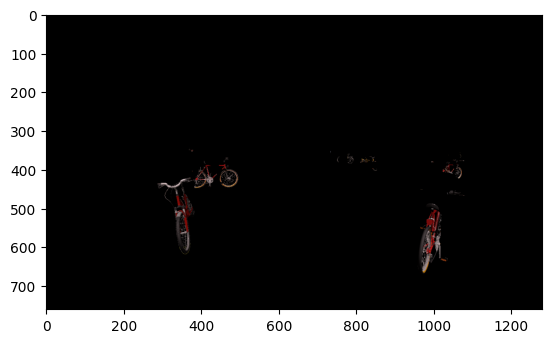

In [167]:
masked_img = torch.mul(src_img_2, MixMask0.squeeze(0).unsqueeze(2))
masked_img = masked_img.squeeze(0).numpy()
masked_img = masked_img.astype(np.uint8)
plt.imshow(masked_img)
plt.show()

1017 527 3 7
959 500 78 171
373 500 1 1
371 495 1 1
372 493 1 1
979 488 35 17
1035 460 3 5
1040 455 41 13
969 452 5 1
966 451 1 1
392 442 1 1
386 442 1 2
466 440 1 1
395 440 1 1
384 440 1 1
480 438 1 1
474 438 1 1
469 437 1 2
467 437 1 1
464 437 1 1
462 436 1 1
465 435 1 1
473 434 1 1
468 434 1 1
477 433 1 1
475 432 1 1
465 432 1 1
459 432 1 1
478 431 4 2
469 431 1 1
488 430 1 1
472 430 1 1
463 429 1 1
383 429 1 1
482 428 2 2
470 428 1 2
468 428 1 1
488 427 1 1
481 427 1 1
479 427 1 1
461 427 1 2
484 426 1 1
463 426 3 2
454 426 1 1
480 425 1 1
467 425 1 2
458 425 1 1
462 424 1 1
481 421 1 1
454 421 2 1
288 421 96 198
486 420 1 1
1063 419 1 1
1058 419 1 1
464 419 2 1
455 419 1 1
484 418 1 1
481 418 1 1
461 418 1 1
387 418 1 1
487 417 1 1
1062 416 1 1
1059 416 1 1
470 416 1 1
460 416 1 1
456 416 1 1
486 415 1 1
390 415 2 4
477 414 1 1
457 414 1 1
1066 413 1 1
1056 413 1 1
1058 412 1 2
485 412 1 1
474 412 9 8
459 412 2 2
392 412 1 1
473 411 1 2
469 411 1 1
461 411 1 1
1055 410 2 2
480 410

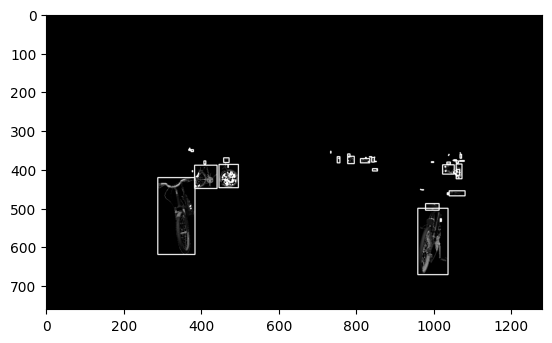

In [174]:
# Assuming you have an image named "image" that you want to find contours on
# Convert tensor to cv2 image

# Convert the image to grayscale
gray = cv2.cvtColor(masked_img, cv2.COLOR_BGR2GRAY)

# Apply thresholding to convert the image to binary
ret, thresh = cv2.threshold(gray, 0.5, 255, cv2.THRESH_BINARY)

# Find contours
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Draw contours on the original image
# contour_image = cv2.drawContours(gray, contours, -1, (0, 255, 0), 2)
# Iterate and draw bounding boxes
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    print(x, y, w, h)
    cv2.rectangle(gray, (x, y), (x+w, y+h), (255, 0, 0), 2)

# Display the image with contours
plt.imshow(cv2.cvtColor(gray, cv2.COLOR_BGR2RGB))
plt.show()


In [170]:
contours

(array([[[1019,  527]],
 
        [[1018,  528]],
 
        [[1018,  531]],
 
        [[1017,  532]],
 
        [[1018,  532]],
 
        [[1019,  533]],
 
        [[1019,  530]],
 
        [[1018,  529]],
 
        [[1018,  528]]], dtype=int32),
 array([[[ 995,  500]],
 
        [[ 994,  501]],
 
        [[ 994,  502]],
 
        [[ 995,  503]],
 
        [[ 997,  503]],
 
        [[1000,  506]],
 
        [[1000,  510]],
 
        [[ 998,  512]],
 
        [[ 997,  511]],
 
        [[ 995,  511]],
 
        [[ 994,  510]],
 
        [[ 994,  509]],
 
        [[ 994,  513]],
 
        [[ 993,  514]],
 
        [[ 992,  514]],
 
        [[ 992,  516]],
 
        [[ 991,  517]],
 
        [[ 991,  518]],
 
        [[ 990,  519]],
 
        [[ 990,  520]],
 
        [[ 989,  521]],
 
        [[ 989,  522]],
 
        [[ 988,  523]],
 
        [[ 988,  525]],
 
        [[ 987,  526]],
 
        [[ 987,  527]],
 
        [[ 986,  528]],
 
        [[ 984,  528]],
 
        [[ 983,  529]],
 

In [106]:
src_lbl_2.unique(return_counts=True)

(tensor([  0.,   1.,   2.,   3.,   5.,   6.,   8.,   9., 250.]),
 tensor([  3538, 172152,  14613,   2507,  30106,   1638,    517,   8886, 738843]))

In [110]:
classes

tensor([5.])

In [111]:
MixMask0.unique(return_counts=True)

(tensor([0, 1]), tensor([942694,  30106]))

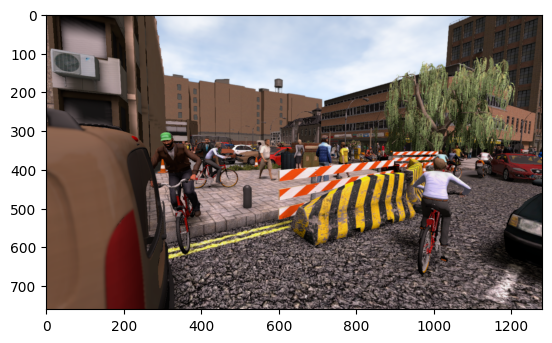

In [32]:
plt.imshow(src_img_2.numpy().astype(np.uint8))

In [11]:
MixMask0.shape

torch.Size([1, 760, 1280])

In [45]:
strong_parameters = {"Mix": MixMask0}
inputs_u_s0, _ = strongTransform(strong_parameters, data = torch.cat((torch.permute(src_img_2.unsqueeze(0), (0, 3, 1, 2)), torch.permute(tgt_img_1.unsqueeze(0), (0, 3, 1, 2)))))

In [59]:
inputs_u_s0.squeeze(0).shape

torch.Size([3, 1024, 2048])

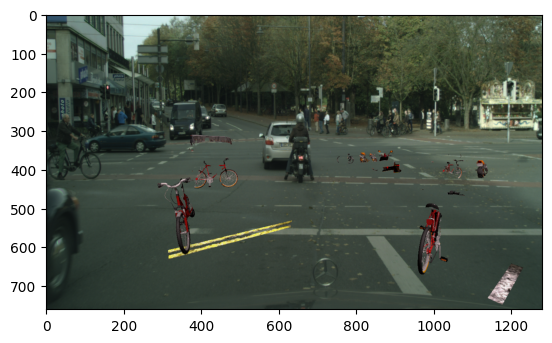

In [46]:
# Display RGB image cv2
import cv2
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = inputs_u_s0.squeeze(0).permute(1, 2, 0).numpy()
img = img.astype(np.uint8)
plt.imshow(img)
plt.show()


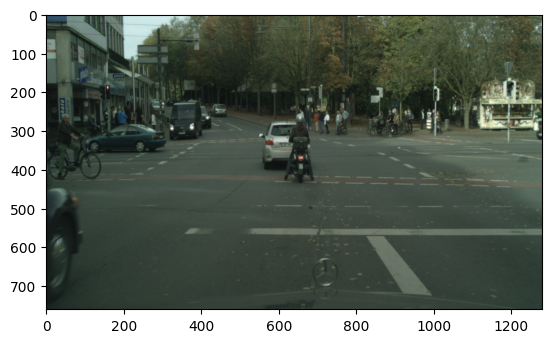

In [31]:
plt.imshow(tgt_img_1.numpy().astype(np.uint8))

In [53]:
torch.permute(tgt_img_1.unsqueeze(0), (0, 3, 1, 2)).shape

torch.Size([1, 3, 1024, 2048])

In [49]:
tgt_img_1.unsqueeze(0)[0].shape

torch.Size([1024, 2048, 3])

In [46]:
tgt_img_1[0].shape

torch.Size([2048, 3])

In [41]:
tgt_img_2.shape

torch.Size([1024, 2048, 3])